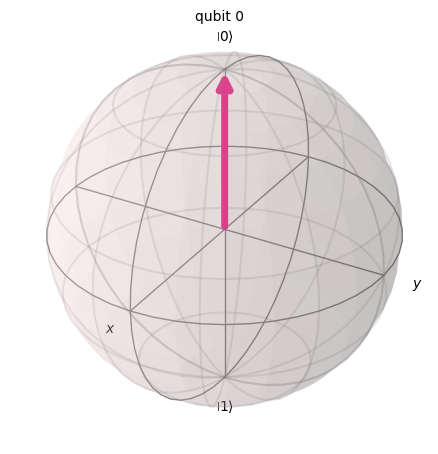

In [13]:
# Initial state |0⟩
sv0 = Statevector.from_label('0')
plot_bloch_multivector(sv0)

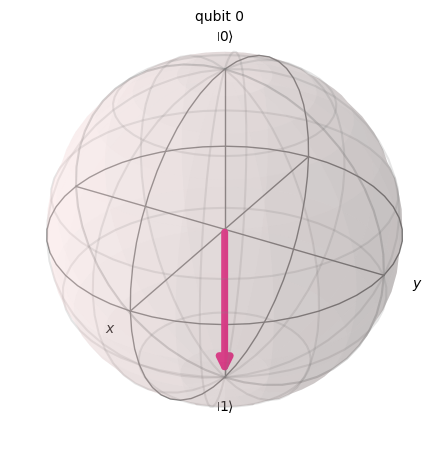

In [11]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
# The bloch sphere drawer is imported from qiskit.visualization
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

qc = QuantumCircuit(1)
qc.x(0)
sv = Statevector(qc)

plot_bloch_multivector(sv)

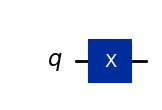

In [10]:
qc.draw(output="mpl", style="iqp")

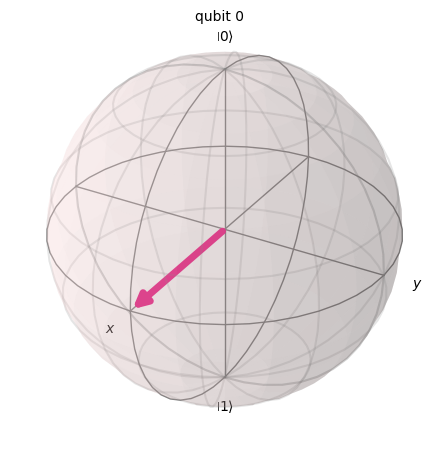

In [16]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
# The bloch sphere drawer is imported from qiskit.visualization
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

qc = QuantumCircuit(1)
qc.h(0)
sv = Statevector(qc)

plot_bloch_multivector(sv)

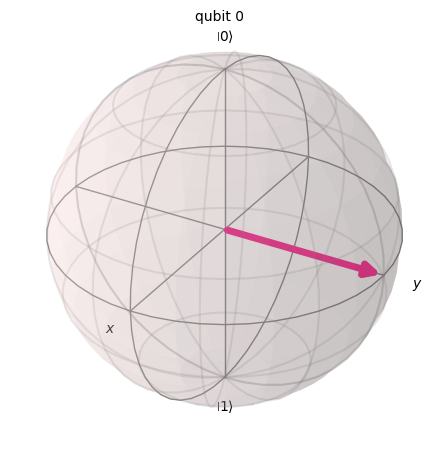

In [18]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

qc = QuantumCircuit(1)
qc.h(0)      # → |+⟩ → +X axis
qc.s(0)      # Adds +90° phase → |+i⟩ → +Y axis  otherwise known as a phase gate.

sv = Statevector(qc)
plot_bloch_multivector(sv)

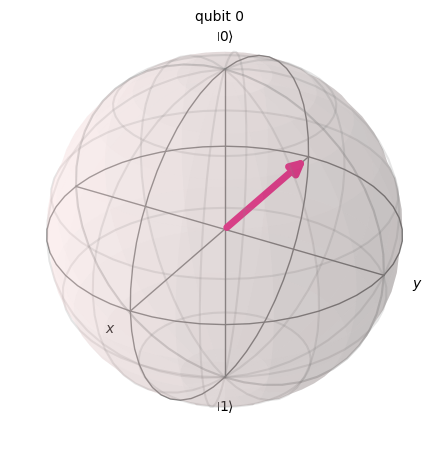

In [19]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

qc = QuantumCircuit(1)
qc.h(0)      # → |+⟩ → +X axis
qc.z(0)      # Adds +90° phase → |+i⟩ → +Y axis  otherwise known as a phase flip (Pauli Z).

sv = Statevector(qc)
plot_bloch_multivector(sv)

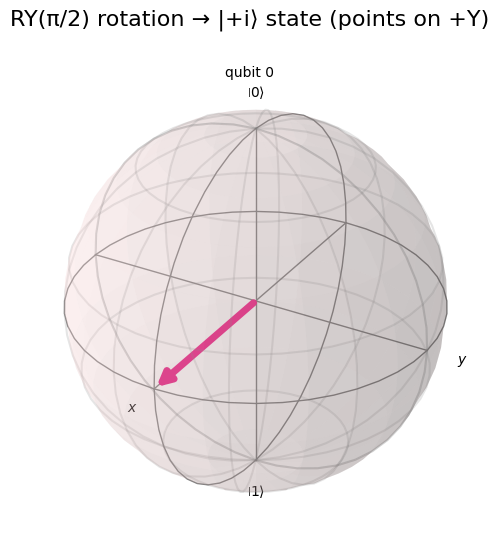

In [5]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
import matplotlib.pyplot as plt

# Start from |0⟩ (default anyway)
qc = QuantumCircuit(1)

# This is the ONLY gate we need to demonstrate Y-rotation
theta = np.pi / 2          # 90° → |0⟩ → |+i⟩ → points exactly on +Y axis
qc.ry(theta, 0)

# Get the final statevector (this is the simplest and correct way)
sv = Statevector(qc)

# Plot
plot_bloch_multivector(sv, title=r"RY(π/2) rotation → |+i⟩ state (points on +Y)")

Done! Here is your perfect Y-axis rotation animation:


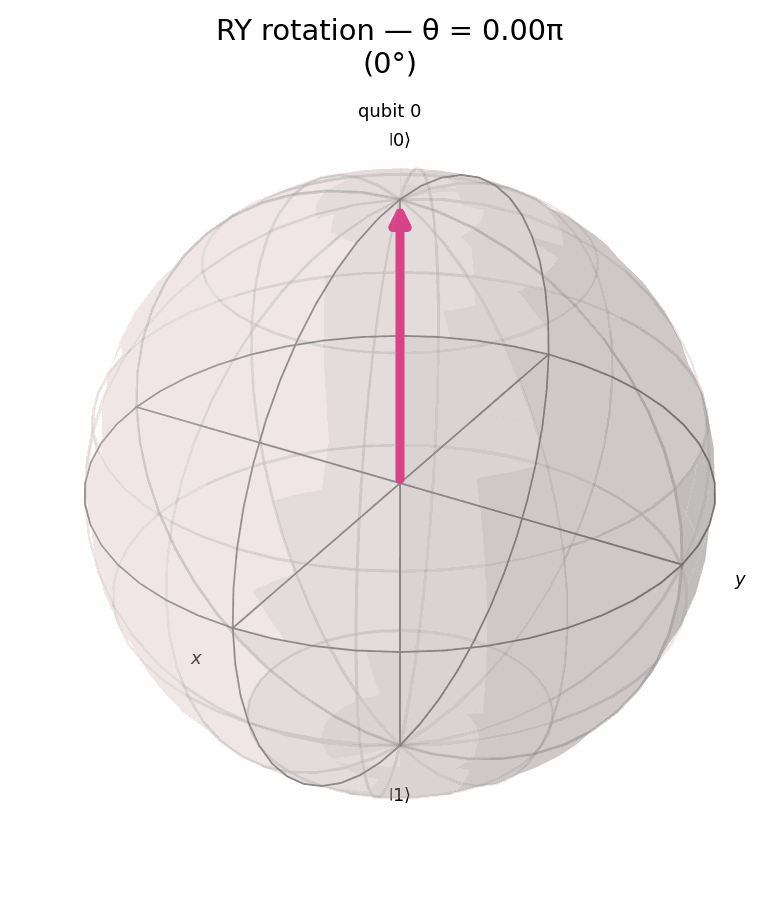

In [4]:
# ONE CELL – WORKS IN JUPYTERLAB RIGHT NOW (no install needed)
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from IPython.display import Image
import imageio.v2 as imageio           # important: v2
import os, glob

# Enable inline high-quality plots
%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['figure.dpi'] = 100

# Generate frames
frames = []
thetas = np.linspace(0, 2*np.pi, 36)   # 36 smooth steps

for i, theta in enumerate(thetas):
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    sv = Statevector(qc)
    
    # This is the line that actually works in JupyterLab:
    fig = plot_bloch_multivector(sv, title=f"RY rotation — θ = {theta/np.pi:.2f}π\n({np.degrees(theta):.0f}°)")
    
    fig.tight_layout()
    filename = f"frame_{i:03d}.png"
    fig.savefig(filename, dpi=130, facecolor='white')
    plt.close(fig)
    frames.append(filename)

# Create GIF
images = [imageio.imread(f) for f in frames]
imageio.mimwrite("RY_rotation_JupyterLab.gif", images, fps=12, loop=0)

# Clean up
for f in frames:
    os.remove(f)

print("Done! Here is your perfect Y-axis rotation animation:")
Image("RY_rotation_JupyterLab.gif")